In [5]:
import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(123)  # reproducible result
os.makedirs("results", exist_ok=True)   # sob output ekhane save hobe

In [6]:
##Dataset Load
import os, io, gzip, zipfile, urllib.request

def load_uci():
    # 1) local csv
    for name in ["Metro_Interstate_Traffic_Volume.csv", "Metro_Interstate_Traffic_Volume.csv.gz"]:
        if os.path.exists(name):
            return pd.read_csv(name)
    # 2) download from UCI
    url = "https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip"
    raw = urllib.request.urlopen(url, timeout=20).read()
    z = zipfile.ZipFile(io.BytesIO(raw))
    fname = z.namelist()[0]
    data = z.read(fname)
    if fname.endswith(".gz"):
        data = gzip.decompress(data)
    return pd.read_csv(io.BytesIO(data))

def make_synthetic(days=365):
    # hourly volume with 2 rush-hour peaks (7-8am, 4-6pm) + noise
    rng = np.random.default_rng(1)
    t = pd.date_range("2017-01-01", periods=days*24, freq="h")
    h = t.hour.values
    base = 800 + 5200*np.exp(-0.5*((h-7.5)/1.5)**2) + 5800*np.exp(-0.5*((h-16.5)/1.8)**2) + 1500*np.exp(-0.5*((h-12)/3)**2)
    vol = base * rng.normal(1, 0.08, len(t))
    return pd.DataFrame({"date_time": t, "traffic_volume": vol.clip(50).astype(int)})

try:
    df = load_uci()
    SOURCE = "UCI Metro Interstate Traffic Volume (real data)"
except Exception as e:
    print("UCI data load hoyni ->", type(e).__name__, "| synthetic data use hocche")
    df = make_synthetic()
    SOURCE = "Synthetic data (UCI pattern er moto)"

df["date_time"] = pd.to_datetime(df["date_time"])
df["hour"] = df["date_time"].dt.hour
print("Data source:", SOURCE)
print("Rows:", len(df))
df[["date_time", "traffic_volume", "hour"]].head()

Data source: UCI Metro Interstate Traffic Volume (real data)
Rows: 48204


,date_time,traffic_volume,hour
0,2012-10-02 09:00:00,5545,9
1,2012-10-02 10:00:00,4516,10
2,2012-10-02 11:00:00,4767,11
3,2012-10-02 12:00:00,5026,12
4,2012-10-02 13:00:00,4918,13


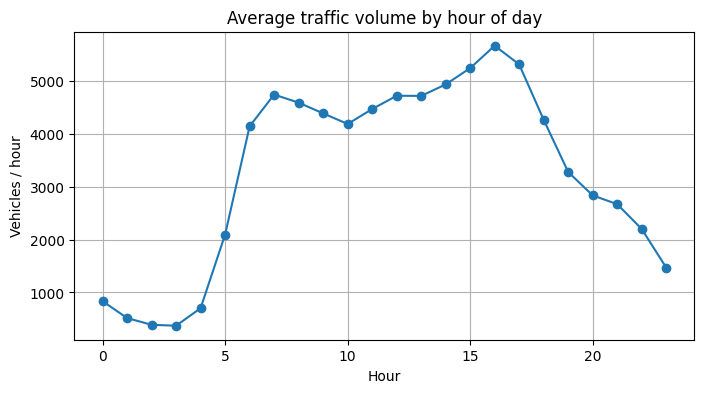

Peak hour: 16 -> 5664 veh/h
Off-peak hour: 3 -> 371 veh/h


In [7]:
##hourly pattern- arrival rate
hourly = df.groupby("hour")["traffic_volume"].mean()

plt.figure(figsize=(8,4))
plt.plot(hourly.index, hourly.values, marker="o")
plt.title("Average traffic volume by hour of day")
plt.xlabel("Hour"); plt.ylabel("Vehicles / hour")
plt.grid(True)
plt.savefig("results/hourly_traffic.png", dpi=150, bbox_inches="tight"); plt.show()

peak_hour = hourly.idxmax()
offpeak_hour = hourly.idxmin()
print("Peak hour:", peak_hour, "->", round(hourly[peak_hour]), "veh/h")
print("Off-peak hour:", offpeak_hour, "->", round(hourly[offpeak_hour]), "veh/h")

In [8]:
#intersection Scalling
SCALE = 0.4
SHARE = {"N": 0.30, "S": 0.30, "E": 0.20, "W": 0.20}

def arrival_rates(volume_per_hour):
    # veh/second for each approach
    return {k: volume_per_hour * SCALE * s / 3600 for k, s in SHARE.items()}

for name, h in [("Peak", peak_hour), ("Off-peak", offpeak_hour)]:
    r = arrival_rates(hourly[h])
    print(name, {k: round(v*3600) for k, v in r.items()}, "veh/h per approach")

Peak {'N': 680, 'S': 680, 'E': 453, 'W': 453} veh/h per approach
Off-peak {'N': 45, 'S': 45, 'E': 30, 'W': 30} veh/h per approach


In [9]:
#Arrival mode validation
lam = arrival_rates(hourly[peak_hour])["N"]          # veh/sec, North approach
n_sec = 3600

arrivals = np.random.poisson(lam, n_sec)             # 1 ghonta, protita second
counts10 = arrivals.reshape(-1, 10).sum(axis=1)      # per 10 sec count

# Chi-square goodness of fit (Poisson)
mu = lam * 10
values = np.arange(0, 7)
obs = np.array([(counts10 == v).sum() for v in values[:-1]] + [(counts10 >= values[-1]).sum()])
exp_p = np.append(stats.poisson.pmf(values[:-1], mu), 1 - stats.poisson.cdf(values[-2], mu)) * len(counts10)
chi2 = np.sum((obs - exp_p)**2 / exp_p)
df_chi = len(obs) - 1                                 # mu known, tai df = bins - 1
crit = stats.chi2.ppf(0.95, df_chi)
print(f"Chi-square = {chi2:.2f}, critical (0.05) = {crit:.2f}")
print("Result:", "Poisson fit kore (fail to reject H0)" if chi2 < crit else "Fit kore na (reject H0)")

# KS test for inter-arrival time
inter = np.random.exponential(1/lam, 2000)
ks_stat, ks_p = stats.kstest(inter, "expon", args=(0, 1/lam))
print(f"KS statistic = {ks_stat:.4f}, p-value = {ks_p:.4f}")
print("Result:", "Exponential fit kore" if ks_p > 0.05 else "Fit kore na")

Chi-square = 9.58, critical (0.05) = 12.59
Result: Poisson fit kore (fail to reject H0)
KS statistic = 0.0187, p-value = 0.4832
Result: Exponential fit kore


In [10]:
#simulation model
SAT_FLOW = 0.5      # veh/sec per green approach
LOST = 3            # sec lost time at each change
PHASE_APPROACHES = {0: ["N", "S"], 1: ["E", "W"]}

def simulate(rates, controller="fixed", duration=3600, fixed_green=30,
             min_green=10, max_green=60, rng=None):
    rng = rng or np.random.default_rng()
    q = {k: 0 for k in rates}            # queue length
    credit = {k: 0.0 for k in rates}     # discharge credit
    phase, green_time, lost_left = 0, 0, 0
    total_delay, arrived, served, max_q = 0, 0, 0, 0

    for t in range(duration):
        # arrivals
        for k, lam in rates.items():
            a = rng.poisson(lam)
            q[k] += a; arrived += a

        if lost_left > 0:
            lost_left -= 1                      # yellow / all-red
        else:
            # discharge
            for k in PHASE_APPROACHES[phase]:
                credit[k] += SAT_FLOW
                go = min(int(credit[k]), q[k])
                q[k] -= go; served += go
                credit[k] -= int(credit[k])
            green_time += 1

            # switch decision
            cur = sum(q[k] for k in PHASE_APPROACHES[phase])
            oth = sum(q[k] for k in PHASE_APPROACHES[1 - phase])
            if controller == "fixed":
                switch = green_time >= fixed_green
            else:
                switch = (green_time >= max_green) or \
                         (green_time >= min_green and cur == 0 and oth > 0)
            if switch:
                phase = 1 - phase
                green_time, lost_left = 0, LOST
                credit = {k: 0.0 for k in credit}

        total_q = sum(q.values())
        total_delay += total_q              # vehicle-seconds
        max_q = max(max_q, max(q.values()))

    avg_delay = total_delay / max(arrived, 1)    # sec per vehicle (Little's law)
    return {"avg_delay": avg_delay, "max_queue": max_q, "throughput": served}

# quick test
r = arrival_rates(hourly[peak_hour])
print("Fixed   :", simulate(r, "fixed",    rng=np.random.default_rng(1)))
print("Adaptive:", simulate(r, "adaptive", rng=np.random.default_rng(1)))

Fixed   : {'avg_delay': 17.258506407423774, 'max_queue': 16, 'throughput': 2251}
Adaptive: {'avg_delay': 11.13610251878038, 'max_queue': 10, 'throughput': 2256}


In [11]:
#monte charlo simulation
N_REP = 30
scenarios = {"Peak": hourly[peak_hour], "Off-peak": hourly[offpeak_hour]}
rows = []

for sc, vol in scenarios.items():
    rates = arrival_rates(vol)
    for ctrl in ["fixed", "adaptive"]:
        for i in range(N_REP):
            rng = np.random.default_rng(1000 + i)    # same seed -> fair comparison
            res = simulate(rates, ctrl, rng=rng)
            rows.append({"scenario": sc, "controller": ctrl, "rep": i, **res})

results = pd.DataFrame(rows)
summary = results.groupby(["scenario", "controller"])[["avg_delay", "max_queue", "throughput"]].mean().round(2)
summary

avg_delay  max_queue  throughput
scenario controller                                  
Off-peak adaptive         3.81       2.10      153.33
         fixed           11.24       3.10      153.30
Peak     adaptive        11.15      11.77     2269.73
         fixed           19.94      18.23     2263.87

In [12]:
#two sample t-test
ttest_rows = []
for sc in scenarios:
    fx = results[(results.scenario == sc) & (results.controller == "fixed")]["avg_delay"].values
    ad = results[(results.scenario == sc) & (results.controller == "adaptive")]["avg_delay"].values

    t_stat, p_val = stats.ttest_ind(fx, ad, equal_var=False)
    diff = fx.mean() - ad.mean()
    se = np.sqrt(fx.var(ddof=1)/len(fx) + ad.var(ddof=1)/len(ad))
    dfree = len(fx) + len(ad) - 2
    ci = stats.t.interval(0.95, dfree, loc=diff, scale=se)

    ttest_rows.append({"scenario": sc, "fixed_mean": fx.mean(), "adaptive_mean": ad.mean(), "diff": diff,
                       "t": t_stat, "p": p_val, "ci_low": ci[0], "ci_high": ci[1]})
    print(f"--- {sc} ---")
    print(f"Fixed mean delay   : {fx.mean():.2f} s")
    print(f"Adaptive mean delay: {ad.mean():.2f} s")
    print(f"Improvement        : {diff:.2f} s ({100*diff/fx.mean():.1f}%)")
    print(f"t = {t_stat:.2f}, p = {p_val:.4g}, 95% CI of diff = [{ci[0]:.2f}, {ci[1]:.2f}]")
    if p_val < 0.05:
        better = "Adaptive" if diff > 0 else "Fixed"
        print(f"Reject H0: dui controller er delay significantly alada. {better} better.\n")
    else:
        print("Fail to reject H0: significant difference nai.\n")

--- Peak ---
Fixed mean delay   : 19.94 s
Adaptive mean delay: 11.15 s
Improvement        : 8.78 s (44.1%)
t = 26.50, p = 1.04e-24, 95% CI of diff = [8.12, 9.45]
Reject H0: dui controller er delay significantly alada. Adaptive better.

--- Off-peak ---
Fixed mean delay   : 11.24 s
Adaptive mean delay: 3.81 s
Improvement        : 7.43 s (66.1%)
t = 34.26, p = 7.916e-30, 95% CI of diff = [6.99, 7.86]
Reject H0: dui controller er delay significantly alada. Adaptive better.



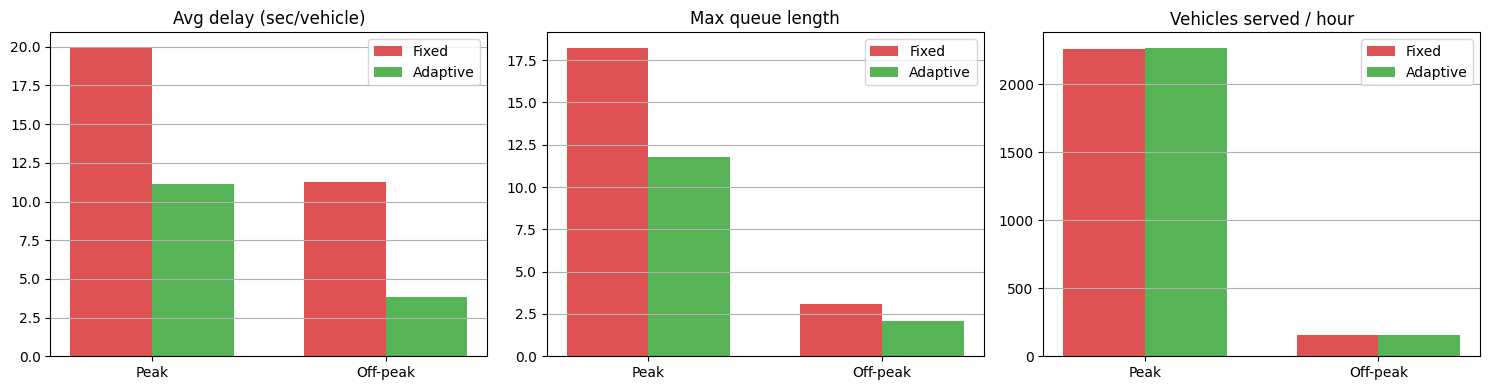

In [13]:
#graphs
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
metrics = [("avg_delay", "Avg delay (sec/vehicle)"), ("max_queue", "Max queue length"), ("throughput", "Vehicles served / hour")]
x = np.arange(len(scenarios)); w = 0.35

for a, (m, title) in zip(ax, metrics):
    f = [results[(results.scenario == s) & (results.controller == "fixed")][m].mean() for s in scenarios]
    d = [results[(results.scenario == s) & (results.controller == "adaptive")][m].mean() for s in scenarios]
    a.bar(x - w/2, f, w, label="Fixed", color="tab:red", alpha=0.8)
    a.bar(x + w/2, d, w, label="Adaptive", color="tab:green", alpha=0.8)
    a.set_xticks(x); a.set_xticklabels(list(scenarios))
    a.set_title(title); a.legend(); a.grid(True, axis="y")
plt.tight_layout()
plt.savefig("results/comparison_bars.png", dpi=150, bbox_inches="tight"); plt.show()

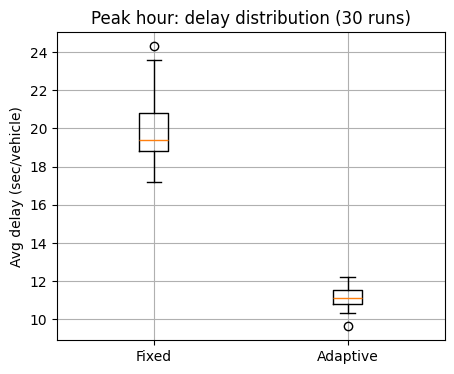

In [14]:
# Box plot: delay distribution over 30 replications (peak hour)
pk = results[results.scenario == "Peak"]
plt.figure(figsize=(5, 4))
plt.boxplot([pk[pk.controller == "fixed"]["avg_delay"], pk[pk.controller == "adaptive"]["avg_delay"]])
plt.xticks([1, 2], ["Fixed", "Adaptive"])
plt.title("Peak hour: delay distribution (30 runs)")
plt.ylabel("Avg delay (sec/vehicle)"); plt.grid(True)
plt.savefig("results/boxplot_peak.png", dpi=150, bbox_inches="tight"); plt.show()

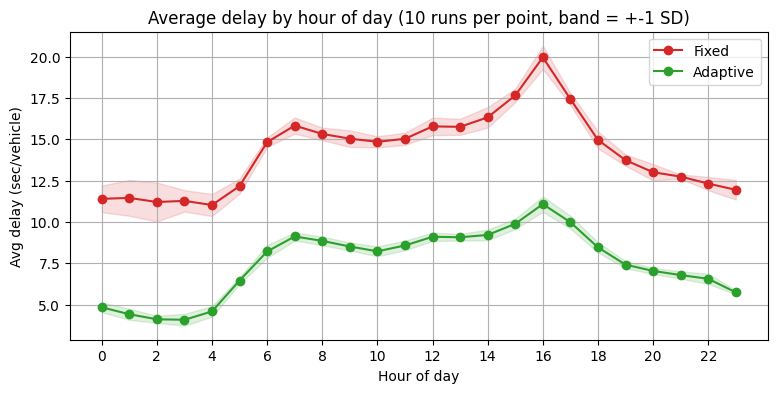

controller,adaptive,fixed,improvement_%
SCALE,,,
0.2,6.93,13.13,47.2
0.3,8.50,14.84,42.7
0.4,11.02,19.22,42.7
0.5,20.93,89.62,76.6
0.6,104.71,238.74,56.1


In [15]:
# (A) 24-hour sweep
sweep = []
for h in range(24):
    rates = arrival_rates(hourly[h])
    for ctrl in ["fixed", "adaptive"]:
        d = [simulate(rates, ctrl, rng=np.random.default_rng(2000 + i))["avg_delay"] for i in range(10)]
        sweep.append({"hour": h, "controller": ctrl, "avg_delay": np.mean(d), "sd": np.std(d, ddof=1)})
sweep = pd.DataFrame(sweep)

plt.figure(figsize=(9, 4))
for ctrl, col in [("fixed", "tab:red"), ("adaptive", "tab:green")]:
    sub = sweep[sweep.controller == ctrl]
    plt.plot(sub.hour, sub.avg_delay, marker="o", label=ctrl.capitalize(), color=col)
    plt.fill_between(sub.hour, sub.avg_delay - sub.sd, sub.avg_delay + sub.sd, color=col, alpha=0.15)
plt.title("Average delay by hour of day (10 runs per point, band = +-1 SD)")
plt.xlabel("Hour of day"); plt.ylabel("Avg delay (sec/vehicle)"); plt.xticks(range(0, 24, 2))
plt.legend(); plt.grid(True)
plt.savefig("results/delay_by_hour.png", dpi=150, bbox_inches="tight"); plt.show()

# (B) Sensitivity to load
sens = []
base_vol = hourly[peak_hour]
for sc in [0.2, 0.3, 0.4, 0.5, 0.6]:
    rates = {k: base_vol * sc * sh / 3600 for k, sh in SHARE.items()}
    for ctrl in ["fixed", "adaptive"]:
        d = [simulate(rates, ctrl, rng=np.random.default_rng(3000 + i))["avg_delay"] for i in range(10)]
        sens.append({"SCALE": sc, "controller": ctrl, "avg_delay": np.mean(d)})
sens = pd.DataFrame(sens)
sens_pivot = sens.pivot(index="SCALE", columns="controller", values="avg_delay").round(2)
sens_pivot["improvement_%"] = (100 * (sens_pivot["fixed"] - sens_pivot["adaptive"]) / sens_pivot["fixed"]).round(1)
sens_pivot

In [16]:
#save result and ZIP
import shutil
results.to_csv("results/all_runs.csv", index=False)
summary.to_csv("results/summary.csv")
sweep.round(3).to_csv("results/sweep_24h.csv", index=False)
sens_pivot.to_csv("results/sensitivity.csv")
pd.DataFrame(ttest_rows).round(4).to_csv("results/ttest_results.csv", index=False)
with open("results/info.txt", "w") as f:
    f.write(f"Data source: {SOURCE}\nRows: {len(df)}\nPeak hour: {peak_hour}\nOff-peak hour: {offpeak_hour}\n")
    f.write(f"SCALE={SCALE}, SHARE={SHARE}, N_REP={N_REP}\n")
    f.write(f"Chi-square={chi2:.2f} (critical {crit:.2f}), KS p={ks_p:.4f}\n")

shutil.make_archive("traffic_results", "zip", "results")
print("Created: traffic_results.zip ->", sorted(os.listdir("results")))

try:
    from google.colab import files
    files.download("traffic_results.zip")
except ImportError:
    print("Colab na, tai folder theke traffic_results.zip nijei nao.")

Created: traffic_results.zip -> ['all_runs.csv', 'boxplot_peak.png', 'comparison_bars.png', 'delay_by_hour.png', 'hourly_traffic.png', 'info.txt', 'sensitivity.csv', 'summary.csv', 'sweep_24h.csv', 'ttest_results.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>